# CA4 - KM and CoxPH on data for stage B/C colon cancer

Link til Panopto video: [https://nmbu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=d52b6d25-2904-4a06-a65b-b4ea00cd076d](https://nmbu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=d52b6d25-2904-4a06-a65b-b4ea00cd076d)

**General information**  
In this compulsory assignment, you will work again with a colon cancer dataset, but this is a different and far larger one than the one you used in CA3. In this dataset, the patients received different treatments, and several covariates/features were recorded for each patient.

<br>

**About the data**  
These are data from one of the first successful trials of adjuvant chemotherapy for colon cancer. Levamisole is a low-toxicity compound previously used to treat worm infestations in animals; 5-FU is a moderately toxic chemotherapy agent. There are two records (rows) per person, one for recurrence of colon cancer and one for death.

<br>

**Feature information**  
id:    id  
study:    1 for all patients  
rx:    Treatment - Obs(ervation), Lev(amisole), Lev(amisole)+5-FU  
sex:    1=male  
age:    in years  
obstruct:    obstruction of colon by tumour  
perfor:    perforation of colon  
adhere:    adherence to nearby organs  
nodes:    number of lymph nodes with detectable cancer  
time:    days until event or censoring  
status:    censoring status  
differ:    differentiation of tumour (1=well, 2=moderate, 3=poor)  
extent:    Extent of local spread (1=submucosa, 2=muscle, 3=serosa, 4=contiguous structures)  
surg:    time from surgery to registration (0=short, 1=long)  
node4:    more than 4 positive lymph nodes  
etype:    event type: 1=recurrence, 2=death  

<br>

The last feature indicates which type of event the row represents. In this compulsory assignment, we consider only data of event type "death".  

The data are available in our DAT350 repository in ../compulsory assignments/CA4  

## Imports

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from skrub import TableReport
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test
from lifelines import CoxPHFitter

## Loading Data

In [42]:
df = pd.read_csv("colon.csv")
df.info()   # Checking for data types

<class 'pandas.DataFrame'>
RangeIndex: 1858 entries, 0 to 1857
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  1858 non-null   int64  
 1   id          1858 non-null   int64  
 2   study       1858 non-null   int64  
 3   rx          1858 non-null   str    
 4   sex         1858 non-null   int64  
 5   age         1858 non-null   int64  
 6   obstruct    1858 non-null   int64  
 7   perfor      1858 non-null   int64  
 8   adhere      1858 non-null   int64  
 9   nodes       1822 non-null   float64
 10  status      1858 non-null   int64  
 11  differ      1812 non-null   float64
 12  extent      1858 non-null   int64  
 13  surg        1858 non-null   int64  
 14  node4       1858 non-null   int64  
 15  time        1858 non-null   int64  
 16  etype       1858 non-null   int64  
dtypes: float64(2), int64(14), str(1)
memory usage: 246.9 KB


## Task 1 - Inspect the data
As always, before modelling starts, one should inspect the data to identify potential outliers, potential skewed distributions of features. Use the skrub TableReport and in addition plot whatever you think is useful or necessary to plot to give you better insight.  

In [43]:
# Using skrub to generate a report for the colon cancer dataset
TableReport(df, title = "Colon Cancer Dataset Report")

Processing column  17 / 17


,,,,,,,,,,,,,,,,,


* Size: 1,858 rows, 17 columns, but only 929 patients. Each patient has 2 rows (etype 1 and 2), so rows are not independent.  
* Unnamed: 0 is just a row number. study has only one value.  
* Missing data: Only nodes (1.9%) and differ (2.5%). It is small, so I should fill with the median or remove those rows.  
* Duplicate information: nodes and node4 are almost the same (0.96).  
* Target columns: time and status are linked (shorter time means the event happened).  

In [44]:
# Dropping missing data
df = df.dropna()

In [45]:
# Making subplots for the histogram of nodes and boxplot of time by etype
fig = make_subplots(rows = 1, cols = 2,
                    subplot_titles = ("nodes", "time by etype"))

# Adding histogram and boxplot to the subplots
fig.add_trace(go.Histogram(x = df["nodes"], nbinsx = 30), row = 1, col = 1)
fig.add_trace(go.Box(x = df["etype"].astype(str), y = df["time"]), row = 1, col = 2)

# Updating layout and showing the figure
fig.update_layout(width = 1200, height = 400, showlegend = False)
fig.show()

* nodes is right-skewed. Most patients have 0 to 5 nodes. A few have more than 20, up to 33. These are the outliers.
* The boxplots show no dots outside the whiskers. Values go from about 0 to 3,300 days.
* etype 1 and 2 are a little different. The median time is 1976 for etype 2 and 1548 for etype 1. The etype 1 box also goes lower (about 350 vs 805), so it has more short times.

**Q1:** Based on your exploratory analysis of the raw data, are there any concerns that need to be addressed? Provide a brief summary (approx. 50 - 100 words).  

<br>
The feature nodes is right-skewed. Missing values in nodes (1.9%) and differ (2.5%) must be filled or removed. I chose to removed them. Some columns are useless: Unnamed: 0 is only a row number, study has one value, and nodes and node4 carry almost the same information. Lastly, rx is text and must be encoded before modelling.

## Task 2 - first insights with Kaplan-Meier curves (lifelines package)

Do an initial exploratory analysis of the data by:

* Plotting of Kaplan-Meier curves based on the covariates features (make sure that censored individuals are shown)
* For covariate/feature "age" you shall split the individuals into three groups using the 34th and 67th percentile. 
* Add the "at-risk counts" tables to each Kaplan-Meier plot
* Carry out appropriate log-rank tests to check whether there are statistically significant differences between survival curves.

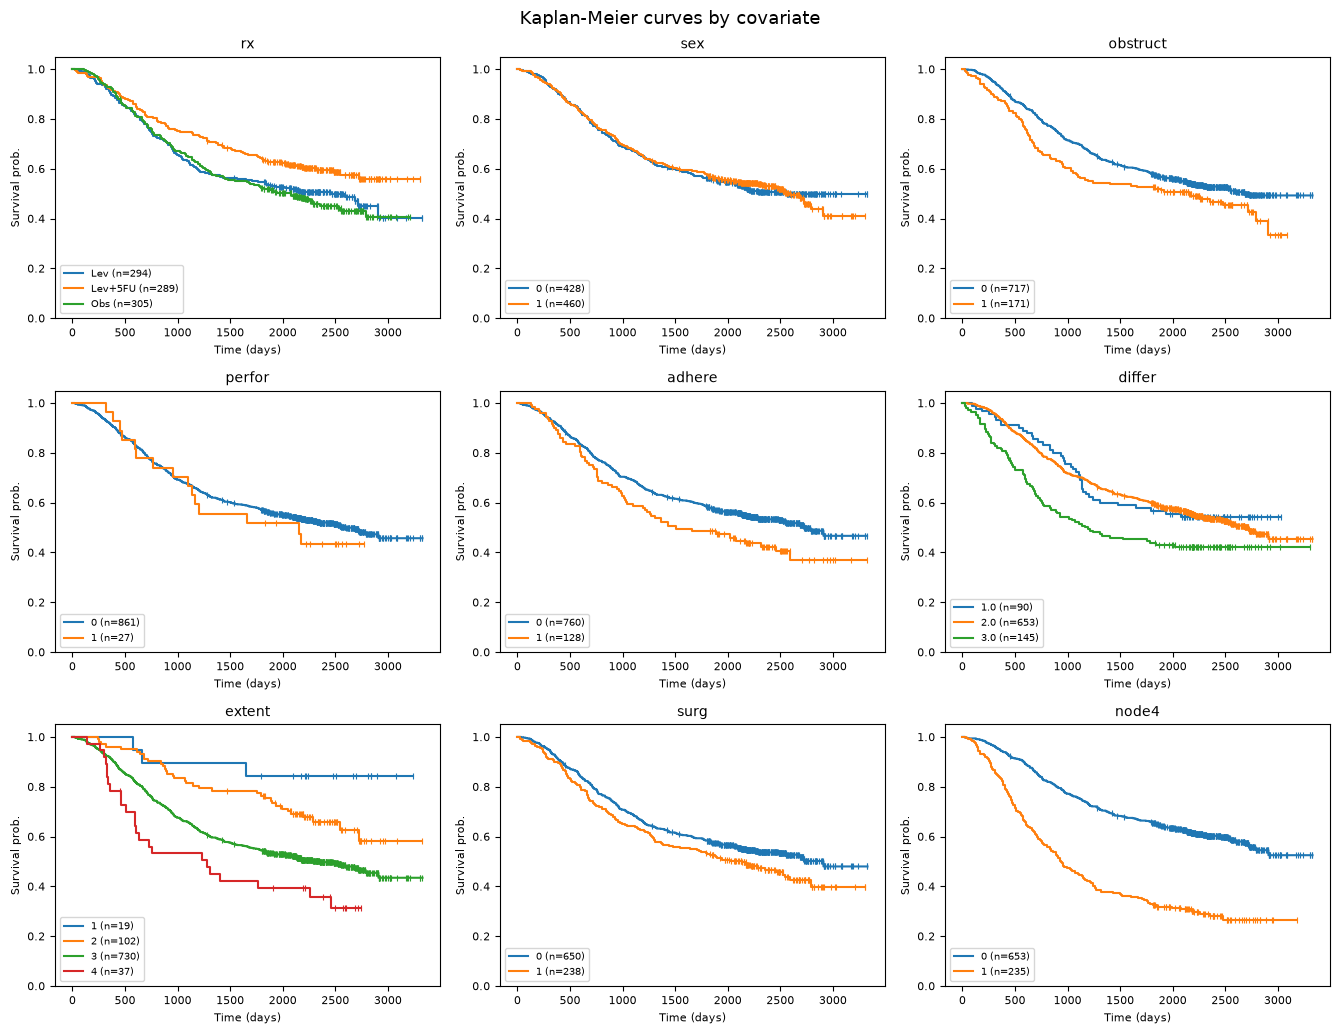

In [46]:
df = df[df["etype"] == 2].copy() # 2 is death

covariates = ["rx", "sex", "obstruct", "perfor", "adhere",
              "differ", "extent", "surg", "node4"] # add "age_group" after step 2

# Kaplan-Meier with function to plot survival curves for each covariate in a grid layout
def km_plot_ax(data, col, ax):
    for g, sub in data.groupby(col, observed=True):
        kmf = KaplanMeierFitter()
        kmf.fit(sub["time"], sub["status"], label=f"{g} (n={len(sub)})")
        kmf.plot_survival_function(
            ax=ax,
            ci_show=False,
            show_censors=True,
            censor_styles={"marker": "|", "ms": 4, "mew": 0.8},
        )
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("Time (days)", fontsize=8)
    ax.set_ylabel("Survival prob.", fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.tick_params(labelsize=8)
    ax.legend(fontsize=7, loc="lower left")

# Function to create a grid of Kaplan Meier plots for multiple covariates
def km_grid(data, cols, ncols=3):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.5 * nrows))
    axes = np.atleast_1d(axes).ravel() # flatten axes array for easy iteration

    # Loop through each covariate and corresponding axis to plot the Kaplan-Meier curves
    for ax, c in zip(axes, cols):
        km_plot_ax(data, c, ax)

    # Hide any unused panels in the grid layout
    for ax in axes[len(cols):]: # hide unused panels
        ax.set_visible(False)

    # Set the overall title for the figure and adjust layout
    fig.suptitle("Kaplan-Meier curves by covariate", fontsize=13)
    plt.tight_layout()
    plt.show()

km_grid(df, covariates)

34th percentile: 56.0, 67th percentile: 66.0
age_group
Low (≤56)      307
Mid (56-66)    294
High (>66)     287
Name: count, dtype: int64


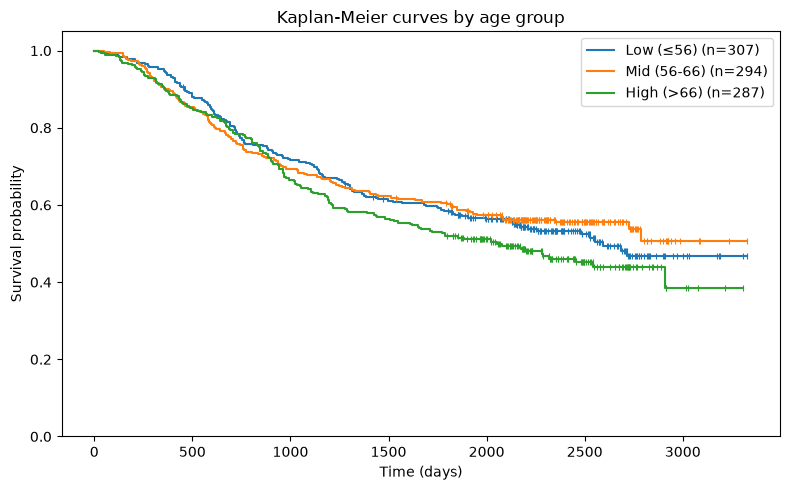

In [47]:
# Creating a new categorical variable for age groups based on the 34th and 67th percentiles of the age distribution.
q34, q67 = df["age"].quantile([0.34, 0.67])
print(f"34th percentile: {q34:.1f}, 67th percentile: {q67:.1f}")

df["age_group"] = pd.cut(
    df["age"],
    bins=[-np.inf, q34, q67, np.inf],
    labels=[f"Low (≤{q34:.0f})", f"Mid ({q34:.0f}-{q67:.0f})", f"High (>{q67:.0f})"],
)
print(df["age_group"].value_counts().sort_index())

# plot it with the same function
fig, ax = plt.subplots(figsize=(8, 5))

for g, sub in df.dropna(subset=["age_group"]).groupby("age_group", observed=True):
    kmf = KaplanMeierFitter()
    kmf.fit(sub["time"], sub["status"], label=f"{g} (n={len(sub)})")
    kmf.plot_survival_function(
        ax=ax,
        ci_show=False,
        show_censors=True,
        censor_styles={"marker": "|", "ms": 4, "mew": 0.8},
    )

ax.set_title("Kaplan-Meier curves by age group")
ax.set_xlabel("Time (days)")
ax.set_ylabel("Survival probability")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

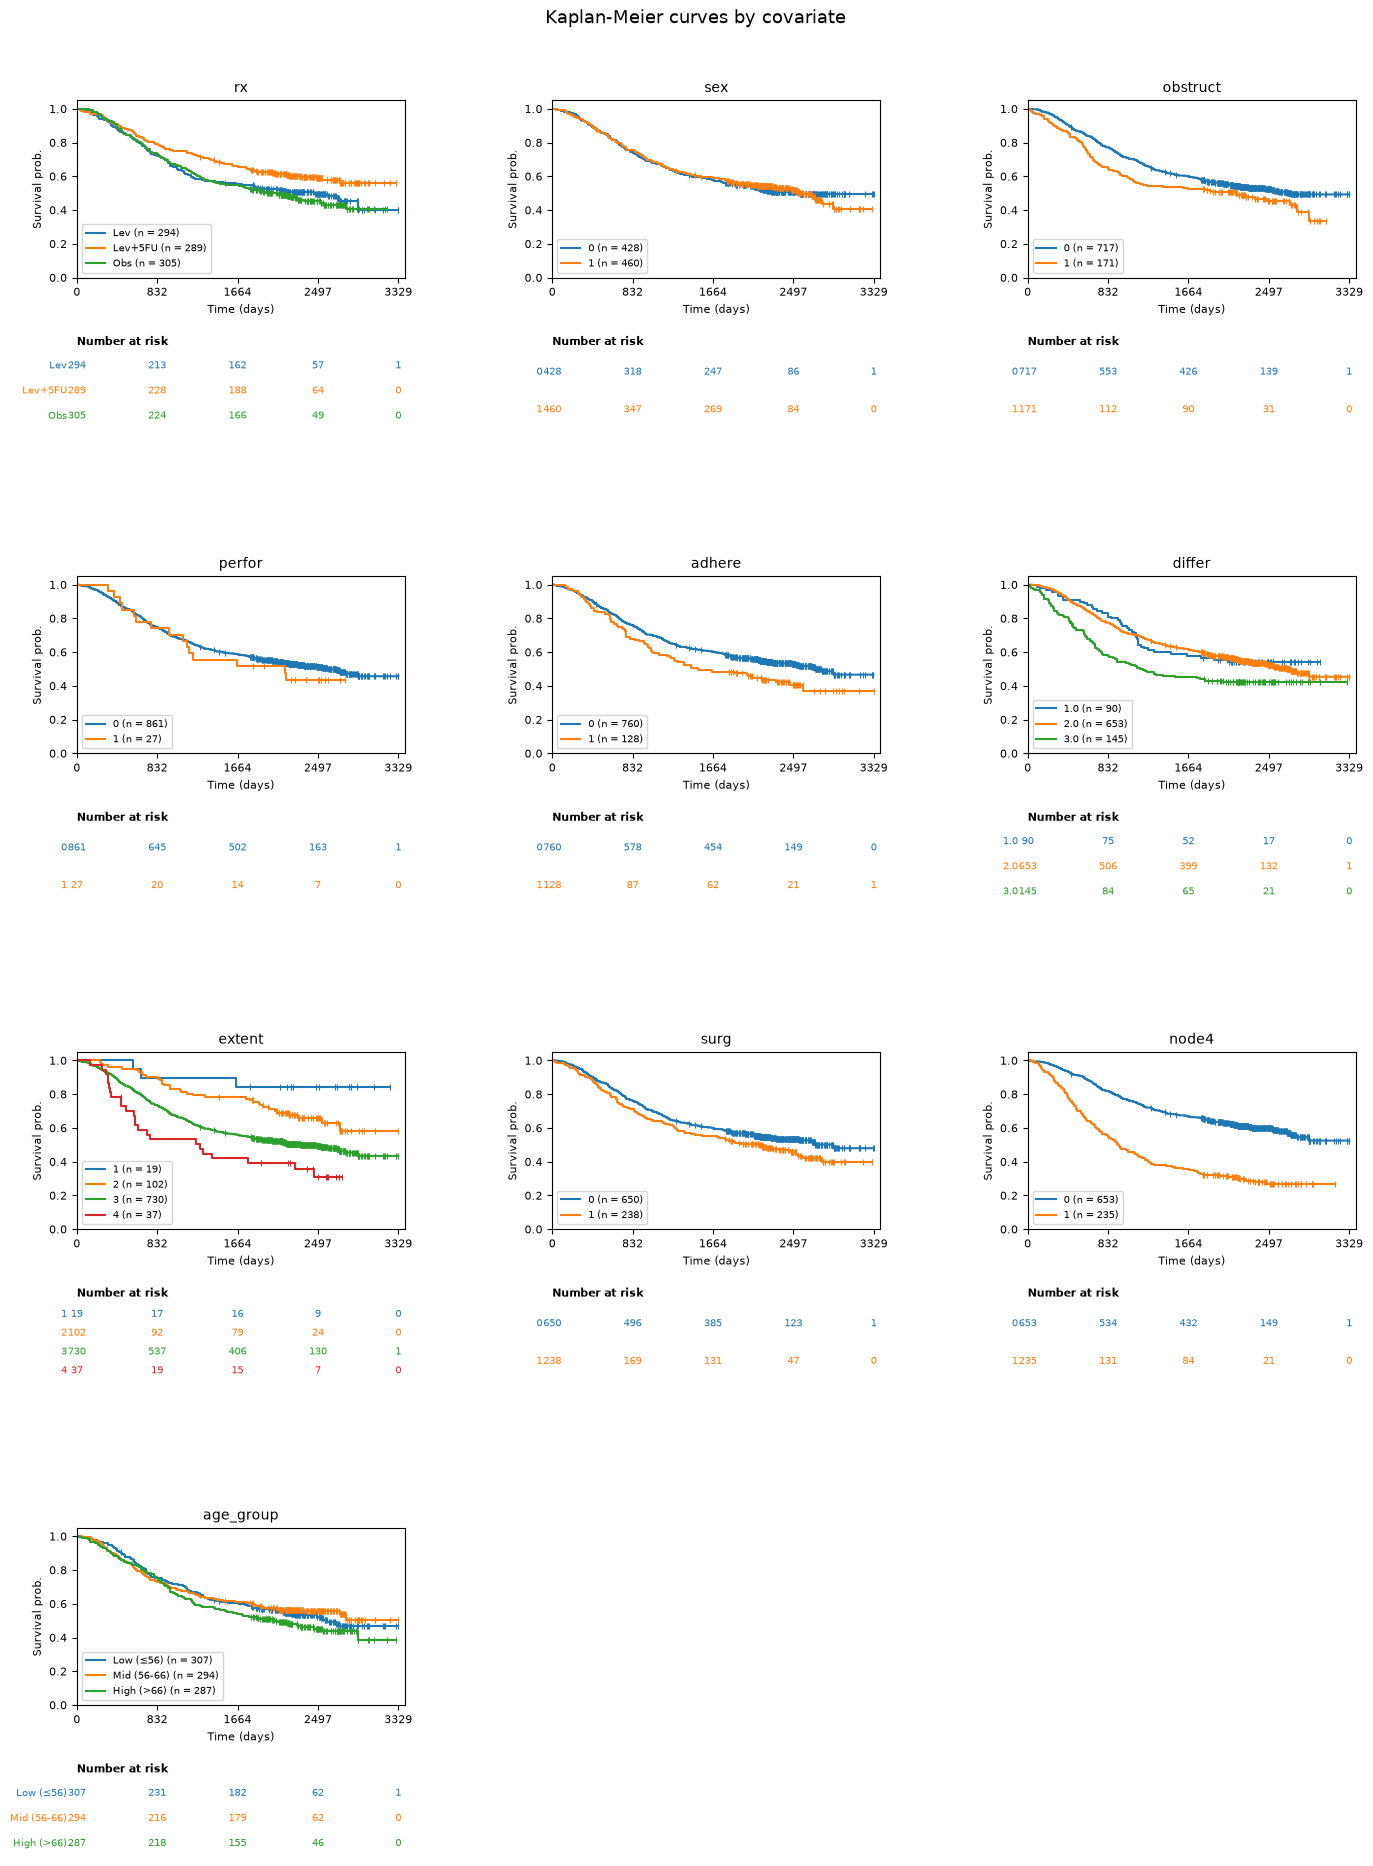

In [48]:
# Function to create a Kaplan-Meier plot with an at-risk table for a single covariate
def km_panel(data, col, ax, tax, n_ticks=5):
    d = data.dropna(subset = [col])
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    groups = []

    # Loop through each group in the covariate and plot the Kaplan-Meier survival function
    for i, (g, sub) in enumerate(d.groupby(col, observed=True)):
        color = colors[i % len(colors)]
        kmf = KaplanMeierFitter()
        kmf.fit(sub["time"], sub["status"], label = f"{g} (n = {len(sub)})")
        kmf.plot_survival_function(
            ax=ax, ci_show = False, show_censors = True,
            censor_styles = {"marker": "|", "ms": 4, "mew": 0.8},
            color=color,
        )
        groups.append((str(g), sub["time"].to_numpy(), color))

    tmax = d["time"].max()
    ticks = np.linspace(0, tmax, n_ticks).round(0)
    ax.set_xticks(ticks)
    ax.set_xlim(0, tmax * 1.02)
    ax.set_ylim(0, 1.05)
    ax.set_title(col, fontsize = 10)
    ax.set_xlabel("Time (days)", fontsize = 8)
    ax.set_ylabel("Survival prob.", fontsize = 8)
    ax.tick_params(labelsize = 8)
    ax.legend(fontsize = 7, loc = "lower left")

    # at-risk table in its own axis under the plot
    tax.set_xlim(ax.get_xlim())
    tax.set_ylim(0, 1)
    tax.axis("off")
    tax.set_title("Number at risk", fontsize = 8, loc = "left", fontweight = "bold")

    # Loop through each group and add the number at risk to the at-risk table
    n = len(groups)
    for r, (name, times, color) in enumerate(groups):
        y = 1 - (r + 0.5) / n
        tax.text(-0.03, y, name, transform = tax.get_yaxis_transform(),
                 ha = "right", va = "center", fontsize = 7, color = color)

        # Add the number at risk for each time point
        for t in ticks:
            tax.text(t, y, int((times >= t).sum()), ha="center", va="center",
                     fontsize = 7, color = color)

def km_grid(data, cols, ncols=3, n_ticks=5):
    nrows = int(np.ceil(len(cols) / ncols))
    max_groups = max(data[c].nunique() for c in cols)
    table_h = 0.35 * max_groups + 0.3

    fig = plt.figure(figsize=(5.5 * ncols, (4 + table_h) * nrows))
    outer = fig.add_gridspec(nrows, ncols, hspace=0.45, wspace=0.45)

    for i, c in enumerate(cols):
        inner = outer[i].subgridspec(2, 1, height_ratios=[4, table_h], hspace=0.6)
        ax = fig.add_subplot(inner[0])
        tax = fig.add_subplot(inner[1])
        km_panel(data, c, ax, tax, n_ticks=n_ticks)

    fig.suptitle("Kaplan-Meier curves by covariate", fontsize=13, y=0.92)
    plt.show()

covariates = ["rx", "sex", "obstruct", "perfor", "adhere",
              "differ", "extent", "surg", "node4", "age_group"]

km_grid(df, covariates, ncols=3)

In [49]:
covariates = ["rx", "sex", "obstruct", "perfor", "adhere",
              "differ", "extent", "surg", "node4", "age_group"]

# Overall log-rank test per covariate
rows = []
for c in covariates:
    d = df.dropna(subset=[c])
    r = multivariate_logrank_test(d["time"], d[c].astype(str), d["status"])
    k = d[c].nunique()
    rows.append({
        "covariate": c,
        "n": len(d),
        "groups": k,
        "chi2": r.test_statistic,
        "df": k - 1,
        "p_value": r.p_value,
        "significant (0.05)": r.p_value < 0.05,
    })

# Display the log-rank test results in a DataFrame, sorted by p-value
logrank_results = pd.DataFrame(rows).sort_values("p_value")
print(logrank_results.round(4).to_string(index=False))

covariate   n  groups    chi2  df  p_value  significant (0.05)
    node4 888       2 99.4450   1   0.0000                True
   extent 888       4 24.2292   3   0.0000                True
   differ 888       3 13.4359   2   0.0012                True
       rx 888       3 11.0169   2   0.0041                True
   adhere 888       2  5.6833   1   0.0171                True
 obstruct 888       2  4.5017   1   0.0339                True
     surg 888       2  3.9845   1   0.0459                True
age_group 888       3  3.8979   2   0.1424               False
   perfor 888       2  0.3811   1   0.5370               False
      sex 888       2  0.0065   1   0.9358               False


**Q2:** What is your interpretation of the KM results so far? Provide a brief summary (approx. 100 - 200 words). 

From the Kaplan-Meier curves and the log-rank tests we can see that survival is different mostly because of how serious the disease is and also the treatment, not because of the patient features like sex. The strongest effect is node4 (more than 4 positive lymph nodes), with chi2 = 99.4 and p < 0.0001. The patients with many positive nodes have survival around 0.27 at the end, while the other group have around 0.52. Extent of the tumour spread is also very significant (p < 0.0001), and the groups 3 and 4 are doing much worse than group 1 and 2. Differ is also significant (p = 0.0012), mostly because the poorly differentiated group (3) have worse survival.

## Task 3 - CoxPH model (lifelines package)

Use the CoxPHFitter class to train models based on the covariates/features, event information, and survival times. Do not tune hyperparameters of the CoxPh model (no cross-validation, no Optuna). 

- You can try various models by adding or removing features
- You can try various models by adding interaction of features
- Use the C-index and partial AIC to determine which model you choose
- Additionally, consider the EPV (events per variable) rule of thumb of EVP

**Note:** since covariate/feature 'age' is time-dependent and we did not discuss models that include time-dependent covariates/features, you should drop it from further analysis. 

In [50]:
base_covs = ["rx", "sex", "obstruct", "perfor", "adhere",
             "differ", "extent", "surg", "node4"]

d = df[["time", "status"] + base_covs].dropna().copy()

# treating these as categorical so they get one dummy per level
for c in ["rx", "differ", "extent"]:
    d[c] = d[c].astype(str)

# Create dummy variables for categorical covariates, dropping the first level to avoid multicollinearity
X = pd.get_dummies(d, columns=["rx", "differ", "extent"], drop_first=True, dtype=float)

n_events = int(X["status"].sum())
print(f"Patients: {len(X)}, events: {n_events}")
print(f"Max parameters allowed by EPV >= 10: {n_events // 10}")
print(list(X.columns))

Patients: 888, events: 430
Max parameters allowed by EPV >= 10: 43
['time', 'status', 'sex', 'obstruct', 'perfor', 'adhere', 'surg', 'node4', 'rx_Lev+5FU', 'rx_Obs', 'differ_2.0', 'differ_3.0', 'extent_2', 'extent_3', 'extent_4']


In [51]:
# Function to fit a Cox proportional hazards model and return the fitted model and summary statistics
def fit_cox(cols, name, data=X):
    cph = CoxPHFitter()
    cph.fit(data[["time", "status"] + cols], duration_col="time", event_col="status")
    k = len(cols)
    return cph, {
        "model": name,
        "n_params": k,
        "EPV": round(n_events / k, 1),
        "C-index": round(cph.concordance_index_, 4),
        "partial AIC": round(cph.AIC_partial_, 2),
    }

# column groups
rx_cols     = [c for c in X.columns if c.startswith("rx_")]
differ_cols = [c for c in X.columns if c.startswith("differ_")]
extent_cols = [c for c in X.columns if c.startswith("extent_")]

models = {
    "M1 full (no interactions)": ["sex", "obstruct", "perfor", "adhere", "surg", "node4"] + rx_cols + differ_cols + extent_cols,
    "M2 drop sex & perfor":       ["obstruct", "adhere", "surg", "node4"] + rx_cols + differ_cols + extent_cols,
    "M3 node4+extent+differ+rx": ["node4"] + rx_cols + differ_cols + extent_cols,
    "M4 node4+extent+rx":        ["node4"] + rx_cols + extent_cols,
    "M5 node4+rx":               ["node4"] + rx_cols,
    "M6 node4 only":             ["node4"],
}

results, fitted = [], {}
for name, cols in models.items():
    fitted[name], row = fit_cox(cols, name)
    results.append(row)

In [52]:
# rx x node4
for c in rx_cols:
    X[f"{c}:node4"] = X[c] * X["node4"]
rx_node4 = [f"{c}:node4" for c in rx_cols]

# surg x node4
X["surg:node4"] = X["surg"] * X["node4"]

# adhere x node4
X["adhere:node4"] = X["adhere"] * X["node4"]

inter_models = {
    "M7 = M3 + rx:node4": models["M3 node4+extent+differ+rx"] + rx_node4,
    "M8 = M3 + surg:node4": models["M3 node4+extent+differ+rx"] + ["surg", "surg:node4"],
    "M9 = M3 + adhere:node4": models["M3 node4+extent+differ+rx"] + ["adhere", "adhere:node4"],
}

for name, cols in inter_models.items():
    fitted[name], row = fit_cox(cols, name)
    results.append(row)

comparison = pd.DataFrame(results).sort_values("partial AIC").reset_index(drop=True)
comparison["EPV ok (>=10)"] = comparison["EPV"] >= 10
print(comparison.to_string(index=False))

                    model  n_params   EPV  C-index  partial AIC  EPV ok (>=10)
     M2 drop sex & perfor        11  39.1   0.6679      5425.66           True
     M8 = M3 + surg:node4        10  43.0   0.6613      5428.83           True
M1 full (no interactions)        13  33.1   0.6678      5429.62           True
M3 node4+extent+differ+rx         8  53.8   0.6567      5430.15           True
   M9 = M3 + adhere:node4        10  43.0   0.6592      5430.88           True
       M4 node4+extent+rx         6  71.7   0.6498      5432.64           True
       M7 = M3 + rx:node4        10  43.0   0.6565      5433.93           True
              M5 node4+rx         3 143.3   0.6245      5446.81           True
            M6 node4 only         1 430.0   0.6044      5454.14           True


<lifelines.CoxPHFitter: fitted with 888 total observations, 458 right-censored observations>
             duration col = 'time'
                event col = 'status'
      baseline estimation = breslow
   number of observations = 888
number of events observed = 430
   partial log-likelihood = -2701.832
         time fit was run = 2026-10-21 12:25:58 UTC

---
             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                    
obstruct    0.234     1.264     0.119           0.001           0.467               1.001               1.595
adhere      0.193     1.213     0.131          -0.063           0.449               0.939               1.567
surg        0.227     1.254     0.106           0.019           0.435               1.019               1.545
node4       0.922     2.515     0.101           0.724           1.120               2.063               3.065
rx_Lev+5FU -0.327     0.721     0.125          -0.571          -0.083               0.565               0.920
rx_Obs      0.032     1.032     0.115          -0.193           0.256               0.825               1.292
differ_2.0 -0.083     0.920     0.168          -0.413           0.246               0.662               1.280
differ_3.0  0.228     1.256     0.196          -0.156           0.612               0.856               1.843
extent_2    0.529     1.698     0.604          -0.654           1.713               0.520               5.546
extent_3    1.023     2.781     0.583          -0.120           2.166               0.887               8.723
extent_4    1.432     4.187     0.618           0.220           2.644               1.246              14.066

            cmp to      z       p  -log2(p)
covariate                                  
obstruct     0.000  1.971   0.049     4.358
adhere       0.000  1.479   0.139     2.847
surg         0.000  2.136   0.033     4.934
node4        0.000  9.135 <0.0005    63.735
rx_Lev+5FU   0.000 -2.627   0.009     6.859
rx_Obs       0.000  0.278   0.781     0.357
differ_2.0   0.000 -0.495   0.621     0.688
differ_3.0   0.000  1.164   0.244     2.033
extent_2     0.000  0.876   0.381     1.393
extent_3     0.000  1.754   0.080     3.653
extent_4     0.000  2.316   0.021     5.606
---
Concordance = 0.668
Partial AIC = 5425.665
log-likelihood ratio test = 132.158 on 11 df
-log2(p) of ll-ratio test = 73.734

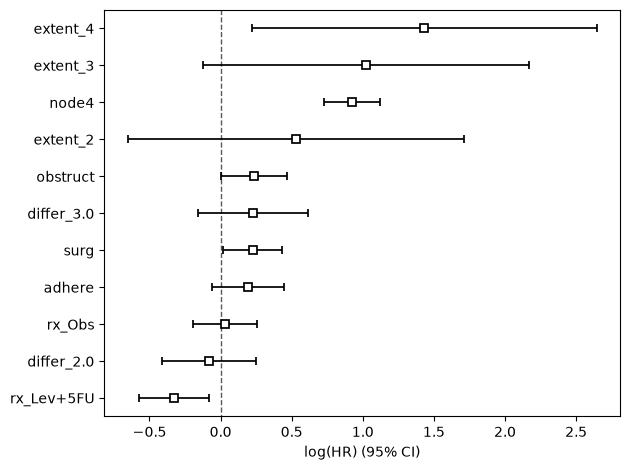

In [53]:
best = fitted["M2 drop sex & perfor"]
best.print_summary(decimals=3)
best.plot()
plt.tight_layout()
plt.show()

**Q3:** What is the interpretation of your best-performing CoxPH model? Provide a brief summary (approx. 100 - 150 words). Address the statistical significance of covariates/features and the value of relevant hazard ratios. Explain how and why you decided that the model you went for is the best choice.  

The best model is M2, with obstruct, adhere, surg, node4, rx, differ and extent, but without sex and perfor. The strongest covariate is node4 (HR = 2.52, p < 0.0005), so patients with more than 4 positive nodes have about 2.5 times higher hazard of death. Lev+5FU have lower hazard than Lev alone (HR = 0.72, p = 0.009), but Obs is not different from Lev (HR = 1.03, p = 0.78). Extent 4 have HR = 4.19 (p = 0.021) compared to extent 1, but the confidence interval is very wide, and extent 2 and 3 are not significant alone. Surg (HR = 1.25, p = 0.033) and obstruct (HR = 1.26, p = 0.049) are borderline, while adhere and differ are not significant. We choose M2 because it has the lowest partial AIC (5425.7), the highest C-index (0.668), and EPV about 39, which is much more than 10. The interactions did not give lower AIC.

<br>

**Q4:** In general, how do the results from your best-performing CoxPH model correspond to the results acquired from the KM curves in Task 2?  

In general the Cox model agree well with the KM curves and log-rank tests. Node4 was the strongest in both, with curves clearly separated and the highest HR. For extent, the KM survival go down when extent is higher, and the Cox HRs also increase (1.7, 2.8, 4.2). For treatment, Lev+5FU was better in the KM curves, while Lev and Obs were similar, and this match the HRs. Adhere, obstruct and surg were weak effects in both analyses, and sex, perfor and age_group were not significant. One difference is differ. It was significant in the log-rank test (p = 0.0012) but not in the Cox model, probably because node4 and extent are correlated with it and explain much of the same effect.

<br>

**Q5:** Specifically, how do the KM survival curves for treatment (feature 'rx') compare to the adjusted survival curves for treatment of your best CoxPH model?  

The adjusted curves show the same picture as the KM curves. Lev+5FU have the highest survival, and Lev and Obs are close to each other and lower. This is the same as the HRs (0.72 for Lev+5FU and 1.03 for Obs). In the KM plot the curves end at about 0.56 for Lev+5FU and about 0.40 for Lev and Obs, and the adjusted curves show a similar gap, because the treatment was randomized so adjusting for the other covariates change little. The difference is that the KM curves are step functions that follow the data, but the adjusted curves are smooth and they can not cross each other because of the proportional hazards assumption. Also, the adjusted curves are for a patient with average values of the other covariates.

# AI Declaration
I used the AI tool ChatGPT to help improve the formulations of my answers to the questions Q1 - Q5. I also used the AI tool to help understand the Lifelines documentation. The interpretation of the results are my own.